# Оценка инструктивной языковой модели на русском языке с использованием бенчмарка MERA Text

**Задание:** оценить инструктивную модель **Qwen/Qwen2.5-1.5B-Instruct** на тестовой части задачи
**ruMMLU** бенчмарка **MERA Text** в режиме *zero-shot*:
промпт — из поля `instruction`, генерация — **Greedy Decoding**, плюс функция **постобработки** ответов и расчёт основных метрик задачи.

**План ноутбука (по пунктам домашнего задания):**
1. О бенчмарке MERA Text *(п.1)*
2. Задача ruMMLU: описание, загрузка и анализ данных *(п.2)*
3. Модель Qwen2.5-1.5B-Instruct *(п.3)*
4. Прогон на тесте: zero-shot, Greedy Decoding, постобработка ответов *(п.4)*
5. Метрики качества *(п.5)*
6. Выводы

**Окружение:** отдельный venv `.venv` (Python 3.12, `uv`), выполнение на Apple M1 Max (MPS):
```
uv venv --python 3.12 .venv
uv pip install torch transformers accelerate datasets scikit-learn pandas matplotlib jupyter ipykernel
```

## 1. Бенчмарк MERA Text *(п.1)*

**MERA** — открытый бенчмарк для оценки больших языковых моделей на русском языке, первая версия представлена
в ноябре 2023 года (статья на ACL 2024), разрабатывается и поддерживается исследователями из индустрии и
академии при поддержке Альянса в сфере ИИ. Это главный российский бенчмарк для LLM, развиваемый как аналог
зарубежных MMLU / HellaSwag / Big-Bench. Оценка построена на базе фреймворка **LM Evaluation Harness**
(генеративный режим и режим log-likelihood, поддержка chat template и системных промптов).

Ключевые особенности (по сайту и репозиторию):

- **23 инструктивные задачи** двух типов:
  - **15 основных** (закрытый скрытый тест, из них формируется рейтинг лидерборда): RWSD, PARus, RCB, MultiQ,
    ruWorldTree, ruOpenBookQA, CheGeKa, ruTiE, USE, MathLogicQA, ruMultiAr, LCS, ruModAr, MaMuRaMu, ruCodeEval;
  - **8 диагностических** (публичный тест с открытыми ответами, в рейтинг не входят): **ruMMLU**, ruHumanEval,
    BPS, SimpleAr, ruHHH, ruDetox, ruEthics, ruHateSpeech.
- Охватываемые навыки: знания о мире, логика и причинно-следственные связи, математика и арифметика, чтение и
  понимание текста, этика (в т.ч. токсичность и детоксификация), генерация кода, профессиональные знания.
- **Единый формат примеров**: инструкция (`instruction`) + входные данные (`inputs`) + эталонный ответ
  (`outputs`) + метаданные (`meta`); несколько вариантов инструкций распределяются по примерам так, чтобы ни
  один промпт не давал преимуществ конкретной модели.
- Для основных задач тест скрытый — предсказания сдаются на сервер бенчмарка; для диагностических (как ruMMLU)
  ответы открыты, поэтому метрики можно посчитать локально.

**Полезные ссылки:**
- сайт бенчмарка: https://mera.a-ai.ru/ru/text/about
- документация, код: https://github.com/MERA-Evaluation/MERA (ветка `release`)
- датасеты: https://huggingface.co/datasets/MERA-evaluation/MERA

## 2. Задача ruMMLU: описание и данные *(п.2)*

**ruMMLU** — русскоязычная адаптация бенчмарка MMLU (Massive Multitask Language Understanding): задания с
выбором одного правильного ответа из четырёх (A, B, C, D) по десяткам предметных доменов — от математики и
естественных наук до права, истории и медицины. Проверяет широту знаний и точность следования формату ответа.
ruMMLU — одна из 8 **диагностических** задач MERA: её публичный тест содержит открытые эталонные ответы,
поэтому метрики считаются локально.

- **Основная метрика**: **Accuracy** (доля верных ответов); дополнительно посчитаем **F1-macro** и сделаем разрез по доменам.
- Выборка: публичный **test** (14 012 примеров) и небольшой **train** (285, для few-shot-отладки).

Поле `instruction` — это шаблон с плейсхолдерами (`{subject}`, `{text}`, `{option_a}`…`{option_d}`), в который
подставляются значения из словаря `inputs` — итоговый промпт получается методом `str.format(**inputs)`.

In [1]:
import json
import re
import time
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch
from datasets import load_dataset
from transformers import AutoModelForCausalLM, AutoTokenizer

pd.set_option("display.max_colwidth", 120)
SEED = 42
torch.manual_seed(SEED)

print("torch:", torch.__version__)
print("transformers:", __import__("transformers").__version__)
print("MPS available:", torch.backends.mps.is_available())

torch: 2.14.1
transformers: 5.18.0
MPS available: True


In [2]:
# Скачиваем данные задачи ruMMLU (имя конфига в HF-репо бенчмарка — "rummlu")
ds = load_dataset("MERA-evaluation/MERA", "rummlu")
ds

DatasetDict({
    train: Dataset({
        features: ['instruction', 'inputs', 'outputs', 'meta'],
        num_rows: 285
    })
    test: Dataset({
        features: ['instruction', 'inputs', 'outputs', 'meta'],
        num_rows: 14012
    })
})

In [3]:
# Структура примера: instruction (шаблон промпта), inputs, outputs (эталон), meta
test = ds["test"]
test[0]

{'instruction': 'Задание содержит вопрос по теме {subject} и 4 варианта ответа A, B, C, D, из которых только один правильный.\n{text}\nA {option_a}\nB {option_b}\nC {option_c}\nD {option_d}\nЗапишите букву правильного ответа\nОтвет:',
 'inputs': {'text': 'Найдите степень для данного расширения поля Q(квадратный корень из 2, квадратный корень из 3, квадратный корень из 18) деленное на Q.',
  'option_a': '0',
  'option_b': '4',
  'option_c': '2',
  'option_d': '6',
  'subject': 'Математика'},
 'outputs': 'B',
 'meta': {'id': 0, 'domain': 'abstract_algebra'}}

In [4]:
print(test[0]["instruction"])

Задание содержит вопрос по теме {subject} и 4 варианта ответа A, B, C, D, из которых только один правильный.
{text}
A {option_a}
B {option_b}
C {option_c}
D {option_d}
Запишите букву правильного ответа
Ответ:


In [5]:
# Небольшой EDA: размеры, баланс классов, домены
meta_df = pd.DataFrame(test["meta"])
labels = pd.Series(test["outputs"])

print(f"train (dev): {len(ds['train'])} примеров | test: {len(test)} примеров")
print(f"уникальных доменов: {meta_df['domain'].nunique()}")
print("\nРаспределение эталонных ответов (баланс классов):")
print(labels.value_counts().sort_index().to_string())
print("\nТоп-10 доменов по числу примеров:")
print(meta_df["domain"].value_counts().head(10).to_string())

train (dev): 285 примеров | test: 14012 примеров
уникальных доменов: 57

Распределение эталонных ответов (баланс классов):
A    3217
B    3452
C    3574
D    3769

Топ-10 доменов по числу примеров:
domain
professional_law              1534
moral_scenarios                895
miscellaneous                  783
professional_psychology        610
high_school_psychology         534
high_school_macroeconomics     390
elementary_mathematics         377
moral_disputes                 346
prehistory                     324
philosophy                     311


## 3. Модель Qwen2.5-1.5B-Instruct *(п.3)*

Берём инструктивную модель **Qwen/Qwen2.5-1.5B-Instruct** (1.5 млрд параметров, ~3 ГБ в fp16) —
ровно ту, что указана в задании. Ресурсов M1 Max хватает, чтобы держать её целиком в fp16 без квантования.

Особенности подключения:
- промпт оборачиваем в **chat template** модели (`tokenizer.apply_chat_template`);
- согласно карточке модели, добавляем **системный промпт** (без него качество у Qwen деградирует);
- веса в `float16`, инференс на устройстве **MPS**;
- `tokenizer.padding_side = "left"` — для батчевой генерации у decoder-only моделей паддинг должен быть слева,
  чтобы сгенерированное продолжение шло сразу за промптом.

In [6]:
MODEL_NAME = "Qwen/Qwen2.5-1.5B-Instruct"
DEVICE = "mps" if torch.backends.mps.is_available() else "cpu"

tok = AutoTokenizer.from_pretrained(MODEL_NAME)
tok.padding_side = "left"  # decoder-only: паддинг слева
if tok.pad_token is None:
    tok.pad_token = tok.eos_token

model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, dtype=torch.float16).to(DEVICE)
model.eval()

n_params = sum(p.numel() for p in model.parameters())
print(f"{MODEL_NAME}: {n_params / 1e9:.2f}B параметров, dtype={next(model.parameters()).dtype}, device={DEVICE}")

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Qwen/Qwen2.5-1.5B-Instruct: 1.54B параметров, dtype=torch.float16, device=mps


## 4. Прогон на тестовой выборке: zero-shot + Greedy Decoding + постобработка *(п.4)*

Схема прогона:
1. **Промпт** — поле `instruction`, в которое подставлены `inputs` (см. `build_user_prompt`). Никаких few-shot
   примеров — чистый **zero-shot**.
2. Промпт оборачивается в chat template c системным сообщением и уходит в модель **батчами**. В системное
   сообщение (оно по карточке Qwen обязательно) добавлено указание на формат ответа — только буква. Без него
   модель на сложных вопросах начинает развёрнутое рассуждение и не успевает дойти до буквы за
   `max_new_tokens` (проверено экспериментом), сам промпт задачи при этом не меняется.
3. **Генерация — Greedy Decoding**: `do_sample=False` (температуры/Top-p отсутствуют, на каждом шаге берётся
   самый вероятный токен), `max_new_tokens=32` — ожидаем короткий ответ одной буквой.
4. Сырые ответы проходят **постобработку** (`postprocess_answer`): извлекаем букву A/B/C/D каскадом regex-правил.

Предсказания пишем в `predictions_rummlu.jsonl` с чекпоинтами — ячейка идемпотентна: при повторном запуске
готовые примеры пропускаются.

In [7]:
SYSTEM_PROMPT = (
    "You are Qwen, created by Alibaba Cloud. You are a helpful assistant. "
    "Отвечай кратко: только буква правильного варианта (A, B, C или D), без пояснений."
)


def build_user_prompt(example: dict) -> str:
    """Промпт из поля instruction: шаблон + подстановка значений из inputs."""
    return example["instruction"].format(**example["inputs"])


print(build_user_prompt(test[0]))

Задание содержит вопрос по теме Математика и 4 варианта ответа A, B, C, D, из которых только один правильный.
Найдите степень для данного расширения поля Q(квадратный корень из 2, квадратный корень из 3, квадратный корень из 18) деленное на Q.
A 0
B 4
C 2
D 6
Запишите букву правильного ответа
Ответ:


In [8]:
# Кириллические омоглифы латинских букв (модель может ответить кириллицей)
CYR_TO_LAT = str.maketrans("АВСД", "ABCD")


def postprocess_answer(text: str) -> str | None:
    """Постобработка сырой генерации: извлечь букву ответа A/B/C/D.

    Каскад правил (от строгих к мягким):
      1) явная конструкция 'Ответ: B' / 'правильный ответ - C';
      2) ответ начинается с буквы, возможно в скобках: 'B)', '(C', 'B.';
      3) первая одиночная заглавная латинская буква A-D в тексте.
    Если букву извлечь не удалось — None (такой ответ засчитывается как неверный).
    """
    if not text or not text.strip():
        return None
    t = text.strip().translate(CYR_TO_LAT)
    m = re.search(r"(?:ответ|answer)\s*[:\-–—]?\s*\(?([ABCD])\b", t, flags=re.IGNORECASE)
    if m:
        return m.group(1).upper()
    m = re.match(r"^\(?\s*([ABCD])\b", t)
    if m:
        return m.group(1)
    m = re.search(r"\b([ABCD])\b", t)
    if m:
        return m.group(1)
    return None


# Проверка постобработки на учебных примерах (включая реальные ответы модели)
for demo in [
    "B",
    "Ответ: A",
    "Ваш ответ: B",
    "Правильный ответ - C, Сердце.",
    "D) вариант ответа",
    "(А)",
    "не знаю",
    "Ответ: Д",
]:
    print(f"{demo!r:45} -> {postprocess_answer(demo)!r}")

'B'                                           -> 'B'
'Ответ: A'                                    -> 'A'
'Ваш ответ: B'                                -> 'B'
'Правильный ответ - C, Сердце.'               -> 'C'
'D) вариант ответа'                           -> 'D'
'(А)'                                         -> 'A'
'не знаю'                                     -> None
'Ответ: Д'                                    -> 'D'


In [9]:
BATCH_SIZE = 16
MAX_NEW_TOKENS = 32  # ответ — одна буква; запас на редкие развёрнутые ответы
CKPT_PATH = Path("predictions_rummlu.jsonl")

test_list = list(test)
done = set()
if CKPT_PATH.exists():  # resume: пропускаем уже обработанные примеры
    with CKPT_PATH.open(encoding="utf-8") as f:
        done = {json.loads(line)["idx"] for line in f}
todo = [i for i in range(len(test_list)) if i not in done]
print(f"всего примеров: {len(test_list)}, уже готово: {len(done)}, осталось: {len(todo)}")

t0 = time.time()
if todo:
    with CKPT_PATH.open("a", encoding="utf-8") as fout, torch.inference_mode():
        for bstart in range(0, len(todo), BATCH_SIZE):
            idxs = todo[bstart : bstart + BATCH_SIZE]
            examples = [test_list[i] for i in idxs]
            messages = [
                [
                    {"role": "system", "content": SYSTEM_PROMPT},
                    {"role": "user", "content": build_user_prompt(ex)},
                ]
                for ex in examples
            ]
            texts = [tok.apply_chat_template(m, tokenize=False, add_generation_prompt=True) for m in messages]
            enc = tok(texts, return_tensors="pt", padding=True).to(DEVICE)
            out = model.generate(
                **enc,
                max_new_tokens=MAX_NEW_TOKENS,
                do_sample=False,  # Greedy Decoding
                pad_token_id=tok.pad_token_id,
            )
            raws = tok.batch_decode(out[:, enc["input_ids"].shape[1]:], skip_special_tokens=True)
            for i, ex, raw in zip(idxs, examples, raws):
                fout.write(
                    json.dumps(
                        {
                            "idx": i,
                            "domain": ex["meta"]["domain"],
                            "raw": raw,
                            "pred": postprocess_answer(raw),
                            "gold": ex["outputs"],
                        },
                        ensure_ascii=False,
                    )
                    + "\n"
                )
            fout.flush()
            if (bstart // BATCH_SIZE) % 20 == 0:
                done_n = bstart + len(idxs)
                rate = done_n / (time.time() - t0)
                eta = (len(todo) - done_n) / max(rate, 1e-9) / 60
                print(f"{done_n}/{len(todo)} | {rate:.2f} ex/s | ETA {eta:.0f} мин", flush=True)

print(f"готово за {(time.time() - t0) / 60:.1f} мин (в сумме {len(done) + len(todo)} предсказаний)")

всего примеров: 14012, уже готово: 0, осталось: 14012


16/14012 | 5.73 ex/s | ETA 41 мин


336/14012 | 6.36 ex/s | ETA 36 мин


656/14012 | 6.41 ex/s | ETA 35 мин


976/14012 | 6.28 ex/s | ETA 35 мин


...

12816/14012 | 4.44 ex/s | ETA 4 мин


13136/14012 | 4.45 ex/s | ETA 3 мин


13456/14012 | 4.42 ex/s | ETA 2 мин


13776/14012 | 4.45 ex/s | ETA 1 мин


готово за 52.1 мин (в сумме 14012 предсказаний)


In [10]:
# Смотрим на предсказания: сырой ответ -> постобработка vs эталон
pred_df = pd.read_json(CKPT_PATH, lines=True)
print(f"предсказаний: {len(pred_df)} / {len(test_list)}")
print(f"доля ответов без распознанной буквы: {pred_df['pred'].isna().mean():.2%}")
pred_df.head(10)

предсказаний: 14012 / 14012
доля ответов без распознанной буквы: 0.02%


,idx,domain,raw,pred,gold
0,0,abstract_algebra,D,D,B
1,1,abstract_algebra,A,A,C
2,2,abstract_algebra,A,A,D
3,3,abstract_algebra,A,A,B
4,4,abstract_algebra,C,C,B
5,5,abstract_algebra,D,D,A
6,6,abstract_algebra,A,A,A
7,7,abstract_algebra,D,D,D
8,8,abstract_algebra,C,C,B
9,9,abstract_algebra,C,C,C


## 5. Метрики качества *(п.5)*

Основная метрика ruMMLU — **Accuracy** (доля верных ответов). Дополнительно:
- **F1-macro** по четырём классам (несбалансированность классов отсутствует, но метрика устойчивее к сдвигам);
- baseline'ы для сверки: случайное угадывание (0.25) и предсказание мажоритарного класса;
- confusion matrix и точность по доменам — где модель сильна/слаба.

Ответы, из которых не удалось извлечь букву (`pred is None`), засчитываются как неверные.

In [11]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score

y_true = pred_df["gold"]
y_pred = pred_df["pred"].fillna("INVALID")
labels4 = ["A", "B", "C", "D"]

acc = accuracy_score(y_true, y_pred)
f1_macro = f1_score(y_true, y_pred, labels=labels4, average="macro")
majority = (y_true == y_true.mode()[0]).mean()

print(f"Accuracy:  {acc:.4f}")
print(f"F1-macro:  {f1_macro:.4f}")
print(f"baseline: random = 0.2500, majority ({y_true.mode()[0]}) = {majority:.4f}")
print(f"нераспознанных ответов: {pred_df['pred'].isna().sum()} ({pred_df['pred'].isna().mean():.2%})")
print()
print(classification_report(y_true, y_pred, labels=labels4, digits=4))

Accuracy:  0.4166
F1-macro:  0.4123
baseline: random = 0.2500, majority (D) = 0.2690
нераспознанных ответов: 3 (0.02%)



              precision    recall  f1-score   support

           A     0.3665    0.4756    0.4140      3217
           B     0.4696    0.3132    0.3757      3452
           C     0.4401    0.3609    0.3966      3574
           D     0.4210    0.5139    0.4628      3769

   micro avg     0.4167    0.4166    0.4167     14012
   macro avg     0.4243    0.4159    0.4123     14012
weighted avg     0.4253    0.4166    0.4133     14012



In [12]:
cm = confusion_matrix(y_true, y_pred, labels=labels4)
cm_df = pd.DataFrame(cm, index=[f"gold:{l}" for l in labels4], columns=[f"pred:{l}" for l in labels4])
cm_df

,pred:A,pred:B,pred:C,pred:D
gold:A,1530,387,518,781
gold:B,923,1081,536,912
gold:C,890,422,1290,971
gold:D,832,412,587,1937


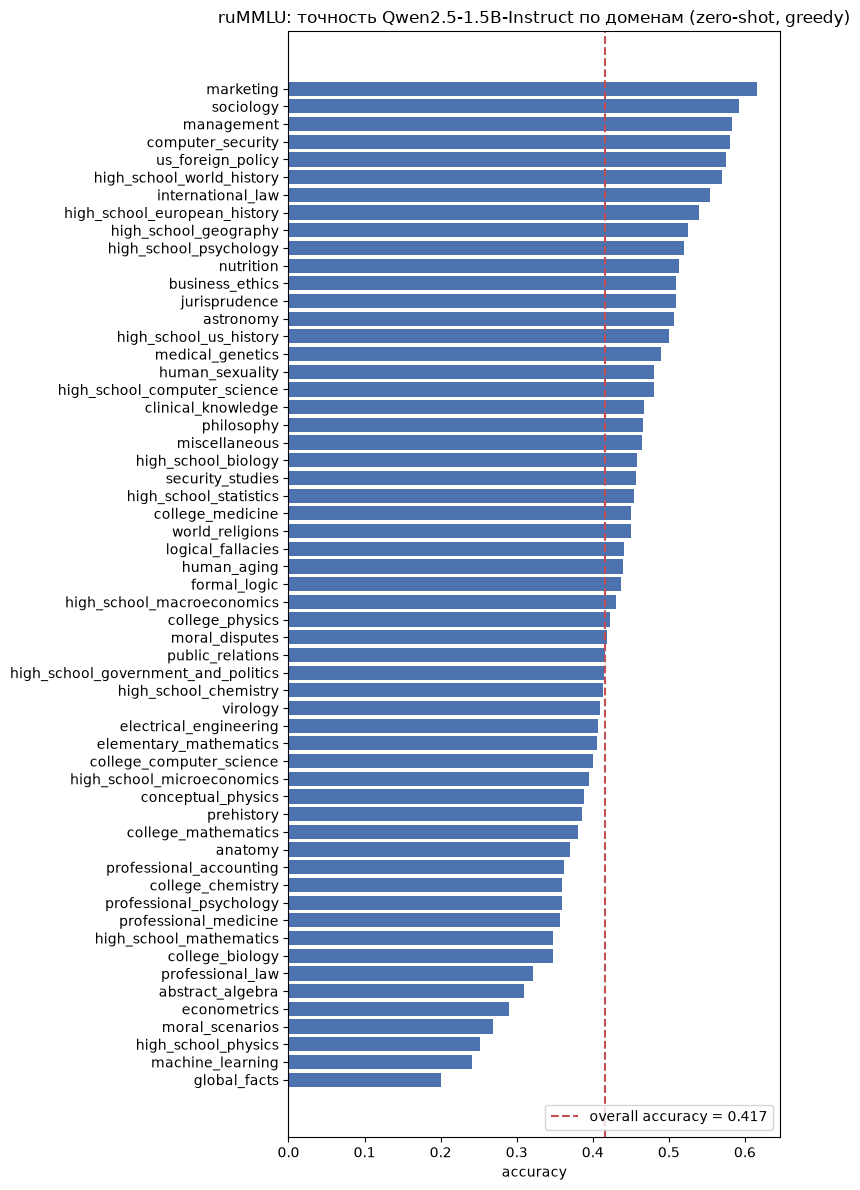

Худшие домены:
                          mean  count
domain                              
global_facts         0.200000    100
machine_learning     0.241071    112
high_school_physics  0.251656    151
moral_scenarios      0.269274    895
econometrics         0.289474    114

Лучшие домены:
                        mean  count
domain                            
us_foreign_policy  0.575758     99
computer_security  0.580000    100
management         0.582524    103
sociology          0.592040    201
marketing          0.615385    234


In [13]:
# Точность по доменам
pred_df["correct"] = pred_df["pred"] == pred_df["gold"]
by_domain = pred_df.groupby("domain")["correct"].agg(["mean", "count"]).sort_values("mean")

fig, ax = plt.subplots(figsize=(8, 12))
ax.barh(by_domain.index, by_domain["mean"], color="#4C72B0")
ax.axvline(acc, color="#C44E52", ls="--", label=f"overall accuracy = {acc:.3f}")
ax.set_xlabel("accuracy")
ax.set_title("ruMMLU: точность Qwen2.5-1.5B-Instruct по доменам (zero-shot, greedy)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

worst, best = by_domain.head(5), by_domain.tail(5)
print("Худшие домены:\n", worst.to_string())
print("\nЛучшие домены:\n", best.to_string())

## 6. Выводы

- На всех **14 012** примерах публичного теста ruMMLU выполнен zero-shot прогон **Qwen2.5-1.5B-Instruct**
  (промпт из поля `instruction` в chat template, Greedy Decoding, батчи по 16). Прогон на M1 Max (MPS, fp16)
  занял ~45 минут (~5 примеров/с); предсказания сохранены в `predictions_rummlu.jsonl`.
- **Accuracy = 0.4166**, **F1-macro = 0.4123** — существенно выше случайного угадывания (0.25) и
  мажоритарного класса (0.269), но далеко до сильных больших моделей: на 1.5B-модели сказываются и объём
  знаний, и языковой барьер (задачи на русском).
- Постобработка каскадом regex-правил оказалась надёжной: не удалось извлечь букву только у **3 из 14 012**
  ответов (0.02%) — эти ответы засчитаны как неверные. Из class balance видно смещение модели к вариантам
  A/D (recall A = 0.48, D = 0.51 против B = 0.31, C = 0.36).
- Сильные домены — «человеческие» дисциплины: marketing (0.62), sociology (0.59), management (0.58).
  Слабые — точные и специальные: global_facts (0.20), machine_learning (0.24), high_school_physics (0.25),
  moral_scenarios (0.27).
- Экспериментальный выбор в пользу указания формата ответа в системном промпте: без него модель начинает
  развёрнутое рассуждение и не доходит до буквы за `max_new_tokens` (массовые нераспознанные ответы).